Bagging dengan Random Forest dan Extra Trees

Persiapan dan membaca dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

data = pd.read_csv("data/WineQT.csv")
print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Dataset berisi karakteristik kimia wine dan kolom `quality` sebagai target. Kolom `Id` hanya merupakan identitas data, sehingga tidak digunakan sebagai fitur model.

In [2]:
X = data.drop(columns=["quality", "Id"])
y = data["quality"]

print("Jumlah fitur:", X.shape[1])
print("Distribusi kelas target:")
display(y.value_counts().sort_index())

Jumlah fitur: 11
Distribusi kelas target:


quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

Membagi data latih dan data uji

Pembagian dilakukan secara stratifikasi agar proporsi setiap kelas kualitas relatif terjaga pada data latih dan data uji.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (914, 11)
Data uji: (229, 11)


Random Forest dan OOB Error

Random Forest membangun banyak pohon keputusan dari sampel bootstrap dan menggabungkan hasil prediksinya. Dengan `oob_score=True`, sebagian data yang tidak terambil pada bootstrap dapat digunakan untuk memperkirakan performa model.

In [4]:
n_trees = [25, 50, 100, 150, 200]
rf_oob_errors = []

for n in n_trees:
    rf = RandomForestClassifier(
        n_estimators=n,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    rf_oob_errors.append(1 - rf.oob_score_)

rf_oob_errors

[0.38293216630196936,
 0.3544857768052516,
 0.34463894967177244,
 0.33150984682713347,
 0.3304157549234136]

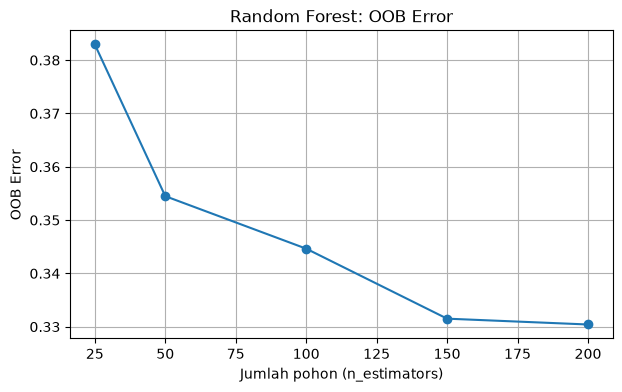

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(n_trees, rf_oob_errors, marker="o")
plt.xlabel("Jumlah pohon (n_estimators)")
plt.ylabel("OOB Error")
plt.title("Random Forest: OOB Error")
plt.grid(True)
plt.show()

Extra Trees

Extra Trees juga menggabungkan banyak pohon keputusan, tetapi menggunakan pemilihan pemisahan (*split*) yang lebih acak. Di sini, kita membandingkan OOB error-nya dengan Random Forest.

In [6]:
et_oob_errors = []

for n in n_trees:
    et = ExtraTreesClassifier(
        n_estimators=n,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )
    et.fit(X_train, y_train)
    et_oob_errors.append(1 - et.oob_score_)

comparison = pd.DataFrame({
    "Random Forest": rf_oob_errors,
    "Extra Trees": et_oob_errors
}, index=n_trees)
comparison.index.name = "Jumlah Pohon"
display(comparison)

,Random Forest,Extra Trees
Jumlah Pohon,,
25,0.382932,0.374179
50,0.354486,0.354486
100,0.344639,0.351204
150,0.331510,0.341357
200,0.330416,0.329322


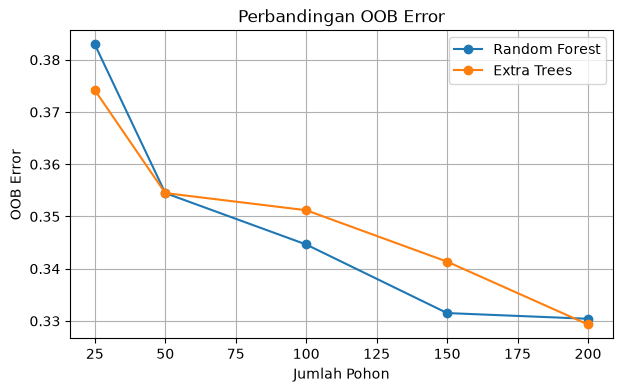

In [7]:
comparison.plot(marker="o", figsize=(7, 4))
plt.ylabel("OOB Error")
plt.title("Perbandingan OOB Error")
plt.grid(True)
plt.show()

Evaluasi model pada data uji

Gunakan model dengan 100 pohon untuk melihat hasil prediksi pada data uji. Metrik yang ditampilkan meliputi akurasi serta precision, recall, dan F1-score per kelas.

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7162
\nClassification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.74      0.85      0.79        97
           6       0.69      0.74      0.71        92
           7       0.74      0.48      0.58        29
           8       0.00      0.00      0.00         3

    accuracy                           0.72       229
   macro avg       0.36      0.34      0.35       229
weighted avg       0.68      0.72      0.69       229



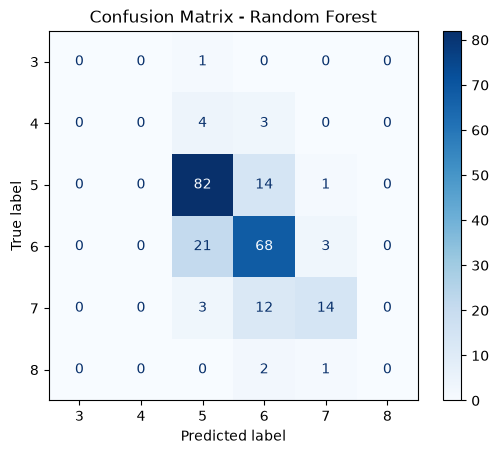

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Random Forest")
plt.show()

Feature Importance

Random Forest dapat memberikan nilai *feature importance* untuk menunjukkan fitur yang paling banyak berkontribusi dalam pemisahan data pada pohon-pohon model.

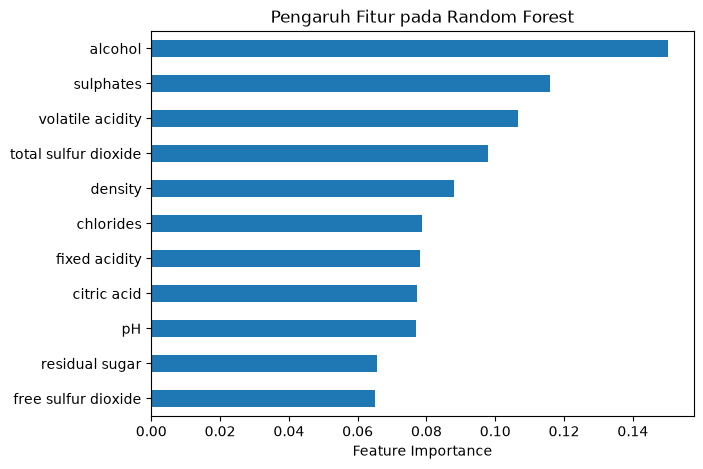

In [10]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(7, 5))
importance.plot(kind="barh")
plt.xlabel("Feature Importance")
plt.title("Pengaruh Fitur pada Random Forest")
plt.show()

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.